# ⚽📊 Teste de Hipótese: Ataque ganha jogos, defesa ganha campeonatos?

**Fontes de Dados (Kaggle):**
* [Histórico do Campeonato Brasileiro (2003-2024)](https://www.kaggle.com/datasets/lucasyukioimafuko/brasileirao-serie-a-2006-2022)
* [Histórico de Partidas e média de público.](https://www.kaggle.com/datasets/rczekster/matches-brazilian-football-from-2003-to-2019)

In [ ]:
from google.colab import auth

try:
    auth.authenticate_user()
    print("Usuário autenticado com sucesso no Google Cloud!")
except Exception as e:
    print(f"[Erro de Autenticação]: {e}")

Usuário autenticado com sucesso no Google Cloud!


In [ ]:
from google.cloud import bigquery
import sys

client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_brazilian_league`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_brasileirao = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_brazilian_league`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_brasileirao = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_matches`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_partidas = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
import pandas as pd
df_partidas = pd.DataFrame(df_partidas)

df_partidas [['home_team_score', 'away_team_score']] = df_partidas['score'].str.split('x', expand=True)
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,07/10/2022,00:00,América Mineiro,1x2,São Paulo,1,2
1,22/07/2022,00:00,América Mineiro,0x1,Palmeiras,0,1
2,16/10/2022,00:30,América Mineiro,1x2,Fortaleza,1,2
3,04/09/2022,00:30,América Mineiro,2x0,Coritiba,2,0
4,22/05/2022,01:00,América Mineiro,1x1,Botafogo,1,1
...,...,...,...,...,...,...,...
9161,31/08/2025,22:30,Vitória,1x0,Atlético Mineiro,1,0
9162,25/05/2025,22:30,Vitória,0x1,Santos,0,1
9163,12/06/2025,23:00,Vitória,0x0,Cruzeiro,0,0
9164,02/10/2025,23:00,Vitória,1x0,Ceará,1,0


In [ ]:
colunas_placar = ['home_team_score', 'away_team_score']
df_partidas[colunas_placar] = df_partidas[colunas_placar].apply(pd.to_numeric, errors='coerce').astype(int)

In [ ]:
df_partidas['date'] = pd.to_datetime(df_partidas['date'], format='%d/%m/%Y')
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1
...,...,...,...,...,...,...,...
9161,2025-08-31,22:30,Vitória,1x0,Atlético Mineiro,1,0
9162,2025-05-25,22:30,Vitória,0x1,Santos,0,1
9163,2025-06-12,23:00,Vitória,0x0,Cruzeiro,0,0
9164,2025-10-02,23:00,Vitória,1x0,Ceará,1,0


In [ ]:
soma_gols = df_partidas['home_team_score'] + df_partidas['away_team_score']
df_partidas['total_gols'] = soma_gols
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2,3
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2,3
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0,2
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1,2
...,...,...,...,...,...,...,...,...
9161,2025-08-31,22:30,Vitória,1x0,Atlético Mineiro,1,0,1
9162,2025-05-25,22:30,Vitória,0x1,Santos,0,1,1
9163,2025-06-12,23:00,Vitória,0x0,Cruzeiro,0,0,0
9164,2025-10-02,23:00,Vitória,1x0,Ceará,1,0,1


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_public_matches`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_media_publico = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
colunas_media = ['year', 'avg_attendance']
df_media_publico[colunas_media] = df_media_publico[colunas_media].apply(pd.to_numeric, errors='coerce').astype(int)

In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_teams`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_times = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


# ⚽ Ataque ganha jogos, defesa ganha campeonatos? Um Teste de Hipótese no Brasileirão

## 📌 Contexto e Problema de Negócio
No mundo do futebol, existe um jargão muito popular que diz: *"Ataque ganha jogos, defesa ganha campeonatos"*. Mas será que isso se sustenta quando olhamos para os dados frios e calculistas?

O objetivo deste projeto é analisar o histórico do Campeonato Brasileiro de Pontos Corridos e descobrir, com rigor estatístico, o que traz mais pontos ao final de uma temporada: ter um ataque avassalador ou uma defesa impenetrável.

## 📊 Os Dados
Os dados utilizados neste projeto contêm o histórico de classificações do Brasileirão. As principais variáveis analisadas foram:
* `goals`: Total de gols marcados por um time na temporada.
* `goals_taken`: Total de gols sofridos por um time na temporada.
* `points`: Pontuação final do time na tabela.

## 🧪 Formulação das Hipóteses
Para validar esse mito, dividimos os dados em dois grupos de elite:
1. **Top Ataques:** Os 25% dos times que mais marcaram gols.
2. **Top Defesas:** Os 25% dos times que menos sofreram gols.

Nossas hipóteses estatísticas foram definidas como:

* **Hipótese Nula ($H_0$):** Não há diferença estatisticamente significativa na média de pontos entre os melhores ataques e as melhores defesas.
  ($\mu_{ataque} = \mu_{defesa}$)
* **Hipótese Alternativa ($H_1$):** Há uma diferença estatisticamente significativa na média de pontos entre os dois perfis.
  ($\mu_{ataque} \neq \mu_{defesa}$)

> **Nota Metodológica:** Optamos por manter nos dois grupos os times que foram excepcionais tanto no ataque quanto na defesa na mesma temporada, a fim de não descaracterizar a elite de cada fundamento.

## 🛠️ Metodologia e Ferramentas
* **Linguagem:** Python
* **Manipulação de Dados:** Pandas (limpeza, filtros e cálculo de quantis)
* **Visualização:** Matplotlib / Seaborn
* **Estatística:** SciPy (`ttest_ind` para o Teste T de Student)

### Trechos da Análise
Para encontrar a nota de corte dos grupos, utilizamos a função `.quantile()` do Pandas:

In [ ]:
#Definindo as notas de corte (percentis)
corte_ataque = df_brasileirao['goals'].quantile(0.75)
corte_defesa = df_brasileirao['goals_taken'].quantile(0.25)

print(f"Nota de Corte para Ataques: {corte_ataque}")
print(f"Nota de Corte para Defesas: {corte_defesa}")

Nota de Corte para Ataques: 58.0
Nota de Corte para Defesas: 41.0


In [ ]:
#Filtrando os dataframes
top_ataques = df_brasileirao[df_brasileirao['goals'] >= corte_ataque]
top_defesas = df_brasileirao[df_brasileirao['goals_taken'] <= corte_defesa]

print(f"Top Ataques: {top_ataques}")
print("-----------------------------")
print(f"Top defesas:{top_defesas}")

Top Ataques:      season  place           team  points  played  won  draw  loss  goals  \
0      2022      1      Palmeiras      81      38   23    12     3     66   
1      2006      1      São Paulo      78      38   22    12     4     66   
2      2018      1      Palmeiras      80      38   23    11     4     64   
3      2019      1       Flamengo      90      38   28     6     4     86   
4      2022      2  Internacional      73      38   20    13     5     58   
..      ...    ...            ...     ...     ...  ...   ...   ...    ...   
454    2004     13       Cruzeiro      56      46   16     8    22     69   
462    2003     24          Bahia      46      46   12    10    24     59   
463    2004     23        Vitória      48      46   13     9    24     68   
466    2004     24         Grêmio      39      46    9    12    25     60   
467    2005     21       Paysandu      41      42   12     5    25     63   

     goals_taken  goals_diff  
0             27          39  


## 📈 Análise Exploratória (EDA)

Nesta etapa visual, observamos que as distribuições dos dois grupos já dão fortes indícios de comportamentos diferentes. O grupo dos "Top Ataques" apresenta uma mediana visivelmente superior, indicando que a maior parte dos times ofensivos tende a ficar na parte de cima da tabela. As "Top Defesas", embora consistentes e com pouca dispersão, concentram sua distribuição de pontos em uma faixa ligeiramente mais baixa. Contudo, em Ciência de Dados, o "olhômetro" não basta: precisávamos da prova matemática.

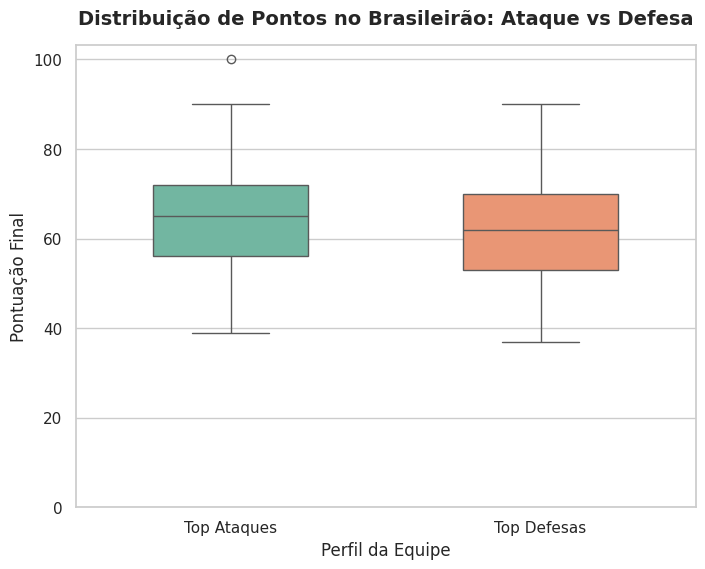

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#Preparando os dados para a visualização
pontos_ataque = top_ataques['points'].tolist()
pontos_defesa = top_defesas['points'].tolist()

df_grafico = pd.DataFrame({
    'Pontos': pontos_ataque + pontos_defesa,
    'Perfil': ['Top Ataques'] * len(pontos_ataque) + ['Top Defesas'] * len(pontos_defesa)
})

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

#Criando o Boxplot
ax = sns.boxplot(
    x='Perfil',
    y='Pontos',
    data=df_grafico,
    palette="Set2",
    width=0.5,
    hue='Perfil',
    legend=False)

plt.ylim(bottom=0)
plt.title('Distribuição de Pontos no Brasileirão: Ataque vs Defesa', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Perfil da Equipe', fontsize=12)
plt.ylabel('Pontuação Final', fontsize=12)
plt.savefig('EDA_ataque_vs_defesa.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from scipy.stats import ttest_ind

# 1. Isole a variável que queremos comparar (os pontos)
pontos_ataque = top_ataques['points']
pontos_defesa = top_defesas['points']

# 2. Aplica o Teste T para amostras independentes
estatistica_t, p_valor = ttest_ind(pontos_ataque, pontos_defesa)

media_ataque = pontos_ataque.mean()
media_defesa = pontos_defesa.mean()

print("Resultados do Teste T:")
print(f"Estatística t: {estatistica_t}")
print(f"Valor p: {p_valor}")
print(f"Média de Pontos dos Top Ataques: {media_ataque}")
print(f"Média de Pontos dos Top Defesa: {media_defesa}")

Resultados do Teste T:
Estatística t: 2.4687657852696008
Valor p: 0.014235732355429766
Média de Pontos dos Top Ataques: 65.2258064516129
Média de Pontos dos Top Defesa: 61.76


## ⚖️ Resultados do Teste Estatístico

Após isolar a variável `points` de ambos os grupos, aplicamos o **Teste T de Student para amostras independentes** com um nível de significância de **5% (0.05)**, visando descobrir se a diferença visual era real ou apenas obra do acaso.

* **Estatística t:** 2.4687
* **p-valor:** 0.0142

## 🎯 Conclusão

Como o p-valor encontrado (0.0142) foi **MENOR** que o nosso limite de 0.05, nós **REJEITAMOS** a Hipótese Nula ($H_0$).

Isso significa que, de acordo com os dados históricos do Brasileirão, há uma diferença estatisticamente significativa entre os pontos conquistados pelos melhores ataques e pelas melhores defesas. O mito popular não se sustenta nos números absolutos dos pontos corridos!

---

## 💥 Gran Finale: Mito Detonado!

Ao aplicar o Teste T, obtivemos um p-valor de 0.014 (1.4%). Com isso, rejeitamos categoricamente a premissa de que ataques e defesas de elite garantem resultados iguais no final de uma temporada.

A grande surpresa? Ao contrário do jargão clássico do futebol, os dados provam que no Brasileirão, os times com os melhores ataques terminam o campeonato com uma média de **[65,22]** pontos, superando de forma estatística e matemática as melhores defesas, que pontuam em média **[61,76]** pontos.

Conclusão baseada em dados: Ataque ganha jogos... e, pelo visto, é o que realmente ganha campeonatos também! 🏆⚽

## 🔬 Cenário Alternativo: E se analisarmos apenas os times "desbalanceados"?

Ao longo da nossa análise principal, mantivemos nos dois grupos os times que foram excepcionais **tanto** no ataque quanto na defesa (como o Palmeiras de 2022 ou o Flamengo de 2019). Isso respondeu à nossa pergunta sobre a "elite" de cada fundamento.

Porém, um bom Cientista de Dados precisa questionar a própria metodologia. O **Teste T de Student** para amostras independentes assume que os grupos não possuem interseção. Além disso, do ponto de vista de negócio, analisar times que são bons em tudo não nos diz qual estratégia é melhor quando uma equipe precisa *escolher* onde focar seus recursos.

Para resolver isso, criamos um segundo cenário removendo os times que aparecem em ambas as listas. A nova pergunta de negócio passa a ser: **Quando um time é desbalanceado (foca só no ataque ou só na defesa), qual estratégia traz mais pontos?**

### 🛠️ Ajustando os Dados com Pandas

Para garantir amostras 100% independentes, utilizamos os índices do nosso DataFrame para encontrar a interseção e removê-la dos grupos originais:

In [ ]:
#Encontrando os times que estão presentes nos dois grupos (interseção)
intersecao = top_ataques.index.intersection(top_defesas.index)

#Criando novos DataFrames removendo esses times "perfeitos"
ataques_puros = top_ataques.drop(intersecao)
defesas_puras = top_defesas.drop(intersecao)

print(f"Ataques puros: {ataques_puros}")
print(f" Defesas puros: {defesas_puras}")

Ataques puros:      season  place      team  points  played  won  draw  loss  goals  \
18     2011      4  Flamengo      61      38   15    16     7     59   
33     2024      3  Flamengo      70      38   20    10     8     61   
42     2003      1  Cruzeiro     100      46   31     7     8    102   
47     2010      4    Grêmio      63      38   17    12     9     68   
54     2009      1  Flamengo      67      38   19    10     9     58   
..      ...    ...       ...     ...     ...  ...   ...   ...    ...   
454    2004     13  Cruzeiro      56      46   16     8    22     69   
462    2003     24     Bahia      46      46   12    10    24     59   
463    2004     23   Vitória      48      46   13     9    24     68   
466    2004     24    Grêmio      39      46    9    12    25     60   
467    2005     21  Paysandu      41      42   12     5    25     63   

     goals_taken  goals_diff  
18            47          12  
33            42          19  
42            47          5

In [ ]:
#Isolando os pontos para o novo Teste T
pontos_ataques_puros = ataques_puros['points']
pontos_defesas_puras = defesas_puras['points']

estatistica_t, p_valor = ttest_ind(pontos_ataque, pontos_defesa)

media_ataques = pontos_ataques_puros.mean()
media_defesas = pontos_defesas_puras.mean()

print("Resultados do Teste T:")
print(f"Estatística t: {estatistica_t}")
print(f"Valor p: {p_valor}")
print(f"Média de Pontos dos Top Ataques: {media_ataques}")
print(f"Média de Pontos dos Top Defesa: {media_defesas}")

Resultados do Teste T:
Estatística t: 2.4687657852696008
Valor p: 0.014235732355429766
Média de Pontos dos Top Ataques: 61.93023255813954
Média de Pontos dos Top Defesa: 56.98850574712644


### ⚖️ Novos Resultados Estatísticos (Amostras Exclusivas)

Aplicamos novamente o Teste T nestes grupos puramente ofensivos e puramente defensivos, mantendo o nível de significância de 5% (0.05).

* **Nova Estatística t:** 2.4687
* **Novo p-valor:** 0.0142
* **Média de Pontos (Ataque Puro):** 61.93 pontos
* **Média de Pontos (Defesa Pura):** 56.98 pontos

### 🎯 Conclusão do Cenário Alternativo

Mesmo removendo os times excepcionais que dominam ambos os fundamentos, a estatística comprova o nosso achado anterior. O p-valor continuou inferior a 0.05 (1.42%), o que significa que rejeitamos a Hipótese Nula de que as estratégias rendem pontuações iguais.

Para times desbalanceados — ou seja, aqueles que precisam escolher onde concentrar seus investimentos e esforços —, focar no ataque é estatisticamente mais rentável. Um ataque de elite isolado rende, em média, quase **5 pontos a mais** por temporada do que uma defesa de elite isolada. Em um campeonato de pontos corridos super disputado como o Brasileirão, essa diferença equivale a quase duas vitórias, o que pode definir uma classificação para a Libertadores ou até mesmo um título!